# Food Orders Across Bahrain, February to July 2024

Food orders in Bahrain's areas rose and fell over six months. The delivery app's teams want to know what happened: which areas and vendors drove the changes, and why.

1. The overall picture: orders by month, area, and vendor.
2. Which vendors grew and which shrank.
3. Hypotheses for the ups and downs, checked against the data.

**Data:** synthetic, generated by [make_data.py](make_data.py): monthly successful orders from 11 vendors in 49 areas of Bahrain. The area names are real places; the vendors and the numbers are made up.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
orders = pd.read_csv("area_orders.csv", parse_dates=["month"])
print(f"{orders.successful_orders.sum():,} orders, {orders.area.nunique()} areas, {orders.vendor.nunique()} vendors")
print(f"area-vendor-months with no orders: {(orders.successful_orders == 0).mean():.0%}")
orders.head()

18,932 orders, 49 areas, 11 vendors
area-vendor-months with no orders: 41%


,month,area,vendor,successful_orders
0,2024-02-01,Madinat Hamad Hamad Town,Grill House,420
1,2024-03-01,Madinat Hamad Hamad Town,Grill House,470
2,2024-04-01,Madinat Hamad Hamad Town,Grill House,528
3,2024-05-01,Madinat Hamad Hamad Town,Grill House,468
4,2024-06-01,Madinat Hamad Hamad Town,Grill House,509


## 1. The overall picture

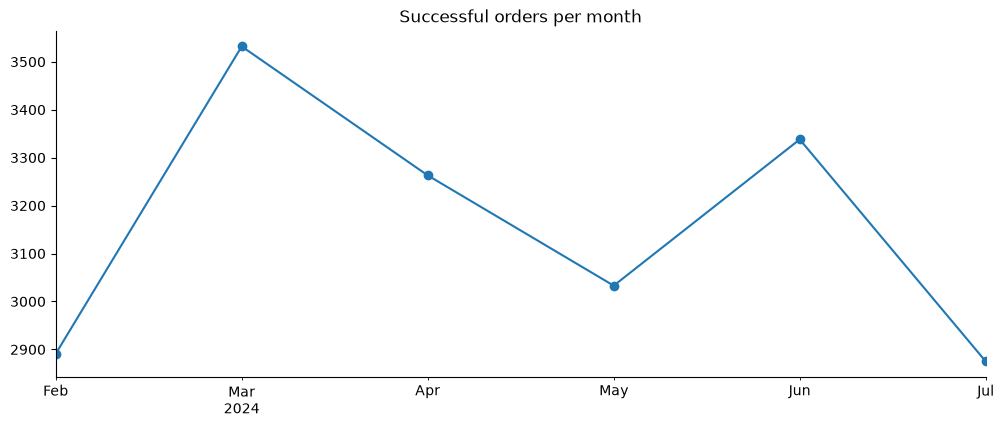

month
2024-02-01     NaN
2024-03-01    22.2
2024-04-01    -7.6
2024-05-01    -7.0
2024-06-01    10.1
2024-07-01   -13.9
Name: change from the month before, %, dtype: float64

In [3]:
monthly = orders.groupby("month").successful_orders.sum()
ax = monthly.plot(marker="o", title="Successful orders per month")
ax.set_xlabel("")
plt.show()
(monthly.pct_change() * 100).round(1).rename("change from the month before, %")

the top 5 areas bring 91% of all orders, the top 10 96%


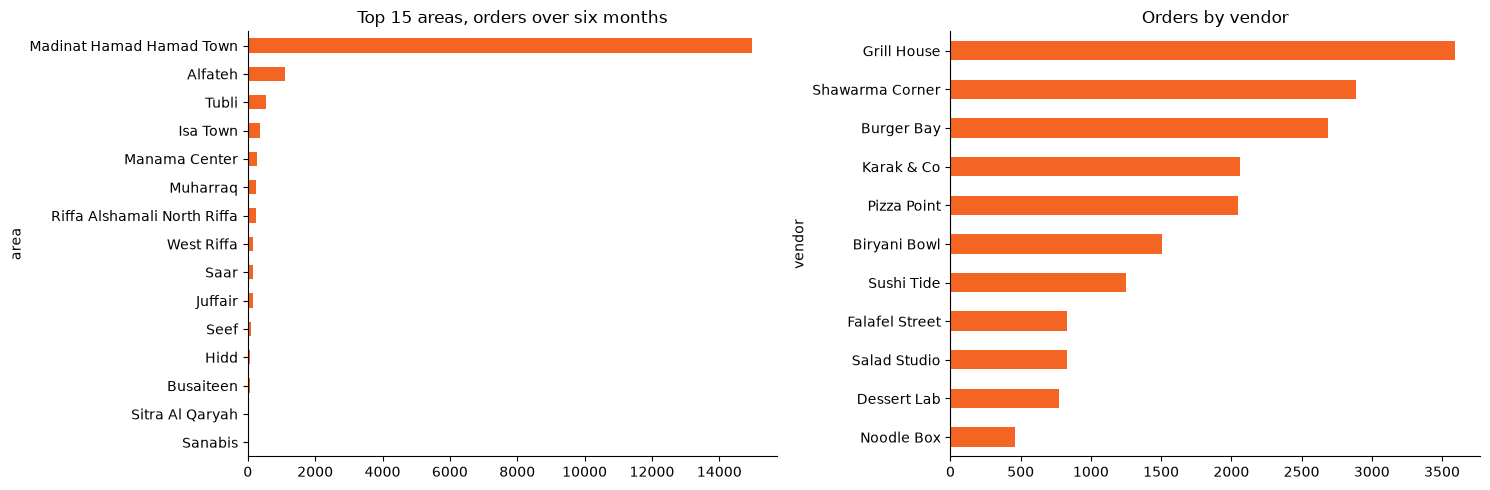

In [4]:
by_area = orders.groupby("area").successful_orders.sum().sort_values(ascending=False)
share = by_area.cumsum() / by_area.sum()
print(f"the top 5 areas bring {share.iloc[4]:.0%} of all orders, the top 10 {share.iloc[9]:.0%}")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
by_area.head(15)[::-1].plot.barh(ax=axes[0], color="#F46524", title="Top 15 areas, orders over six months")
orders.groupby("vendor").successful_orders.sum().sort_values().plot.barh(ax=axes[1], color="#F46524", title="Orders by vendor")
plt.tight_layout()
plt.show()

In [5]:
large = by_area[by_area >= 300].index
orders["area_size"] = np.where(orders.area.isin(large), "300+ orders", "under 300 orders")
orders.groupby("area_size").agg(areas=("area", "nunique"), orders=("successful_orders", "sum"),
                                vendors_present=("vendor", lambda v: v.nunique()))

,areas,orders,vendors_present
area_size,,,
300+ orders,4,16991,11
under 300 orders,45,1941,11


A handful of large areas, Hamad Town above all, make up most of the business, while dozens of small areas each see only a few orders a month, and not every vendor delivers there.

## 2. Which vendors grew

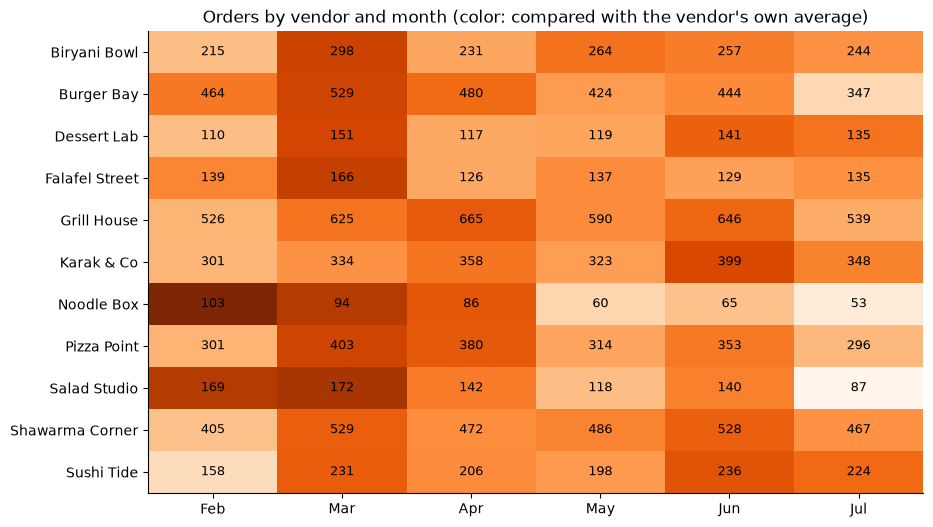

In [6]:
pivot = orders.pivot_table(index="vendor", columns=orders.month.dt.strftime("%b"), values="successful_orders", aggfunc="sum")
pivot = pivot[["Feb", "Mar", "Apr", "May", "Jun", "Jul"]]
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(pivot.div(pivot.mean(axis=1), axis=0), cmap="Oranges", aspect="auto")
ax.set_xticks(range(6), pivot.columns)
ax.set_yticks(range(len(pivot)), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, pivot.iat[i, j], ha="center", va="center", fontsize=9)
ax.set_title("Orders by vendor and month (color: compared with the vendor's own average)")
plt.show()

Raw month-to-month changes mix two things: each vendor's own trend, and moves that hit the whole market at once. A Poisson regression on each vendor's monthly totals separates them: orders depend on the vendor, the month (what the whole market does), and each vendor's growth compared with the market. The vendors' growth figures add up to zero, so a vendor above zero gained share and one below zero lost it.

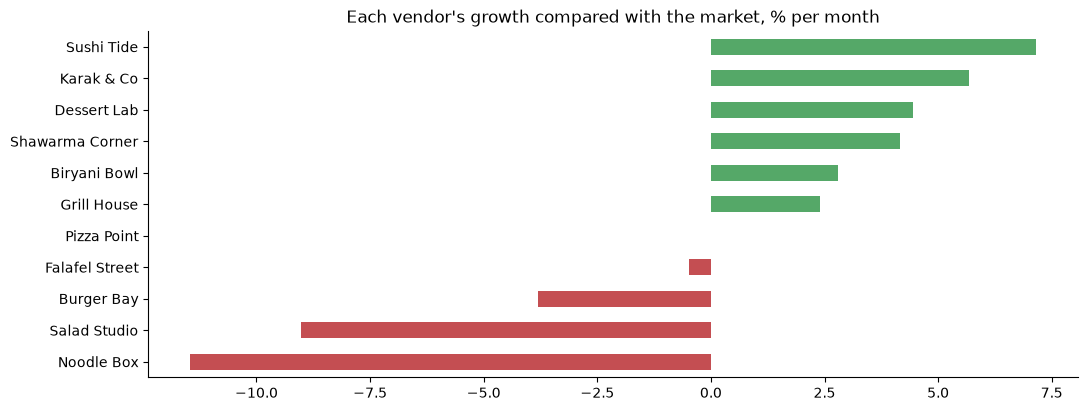

Noodle Box        -11.5
Salad Studio       -9.0
Burger Bay         -3.8
Falafel Street     -0.5
Pizza Point        -0.0
Grill House         2.4
Biryani Bowl        2.8
Shawarma Corner     4.2
Dessert Lab         4.4
Karak & Co          5.7
Sushi Tide          7.2
Name: % per month vs. the market, dtype: float64

In [7]:
totals = orders.groupby(["vendor", "month"], as_index=False).successful_orders.sum()
totals["month_number"] = totals.month.dt.month - 2
totals["month_label"] = totals.month.dt.strftime("%Y-%m")
vendors = sorted(totals.vendor.unique())
last = vendors[-1]
for v in vendors[:-1]:   # each vendor's trend against the last one, so the trends sum to zero
    totals["trend_" + str(vendors.index(v))] = totals.month_number * ((totals.vendor == v).astype(int) - (totals.vendor == last).astype(int))
trend_cols = [c for c in totals.columns if c.startswith("trend_")]
model = smf.glm("successful_orders ~ C(month_label) + C(vendor) + " + " + ".join(trend_cols),
                data=totals, family=sm.families.Poisson()).fit()
trend = pd.Series({v: model.params["trend_" + str(i)] for i, v in enumerate(vendors[:-1])})
trend[last] = -trend.sum()
growth = (np.exp(trend) - 1).sort_values()
ax = (growth * 100).plot.barh(color=np.where(growth > 0, "#55a868", "#c44e52"),
                              title="Each vendor's growth compared with the market, % per month")
plt.show()
(growth * 100).round(1).rename("% per month vs. the market")

## 3. Why orders went up and down

**Hypothesis 1: Ramadan.** In 2024 Ramadan ran from about March 11 to April 9. Families break the fast together at home, and order food late in the evening.

**Hypothesis 2: summer.** From June the heat keeps people indoors, which favors delivery, but in July many residents travel abroad.

If these hypotheses hold, the month effects (what the whole market does in a month, once each vendor's size and trend are taken out) should be high in March and April, high in June, and low in July. And they should hit almost every vendor, not just a few.

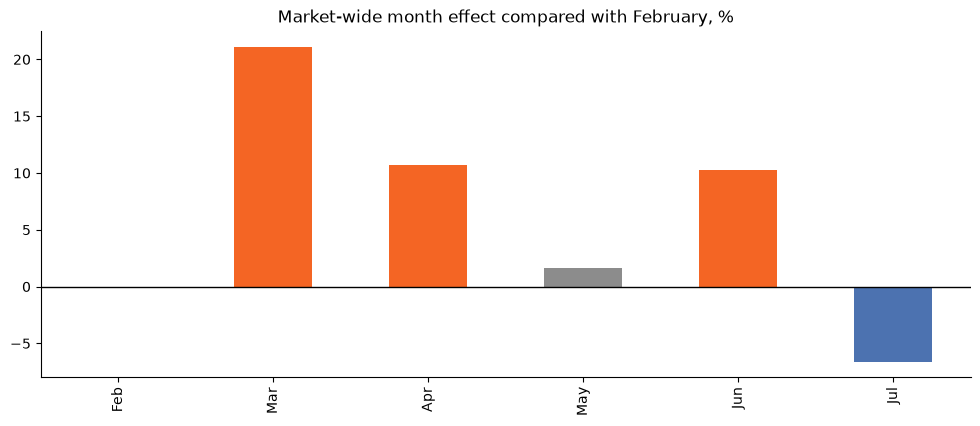

Feb     0.0
Mar    21.1
Apr    10.7
May     1.6
Jun    10.2
Jul    -6.6
Name: vs. February, %, dtype: float64

In [8]:
month_effect = model.params.filter(like="C(month_label)")
month_effect.index = pd.to_datetime(month_effect.index.str.extract(r"(\d{4}-\d{2})")[0]).dt.strftime("%b")
effect = pd.concat([pd.Series({"Feb": 0.0}), month_effect])
effect = (np.exp(effect) - 1) * 100
ax = effect.plot.bar(color=["#8c8c8c", "#F46524", "#F46524", "#8c8c8c", "#F46524", "#4c72b0"],
                     title="Market-wide month effect compared with February, %")
ax.axhline(0, color="black", lw=1)
plt.show()
effect.round(1).rename("vs. February, %")

In [9]:
by_vendor_month = orders.pivot_table(index="vendor", columns=orders.month.dt.strftime("%b"), values="successful_orders", aggfunc="sum")
up_in_march = (by_vendor_month["Mar"] > by_vendor_month["Feb"]).mean()
down_in_july = (by_vendor_month["Jul"] < by_vendor_month["Jun"]).mean()
print(f"vendors with more orders in March than in February: {up_in_march:.0%}")
print(f"vendors with fewer orders in July than in June: {down_in_july:.0%}")

vendors with more orders in March than in February: 91%
vendors with fewer orders in July than in June: 91%


## Results

- Orders rose 22% from February to March, fell back through April and May, rose 10% in June, and dropped 14% in July.
- The business is concentrated: Hamad Town alone brings about four-fifths of all orders, and the top 5 areas 91%. The other 45 areas see only a few orders each, and in 41% of area-vendor-months there are none at all.
- Some vendors gain share and others lose it. Compared with the market, Sushi Tide grows about 7% a month and Karak & Co about 6%, while Noodle Box shrinks about 12% a month and Salad Studio 9%.
- Once each vendor's own trend is taken out, the whole market is 21% above February in March and 11% in April, 10% above in June, and 7% below in July. These moves hit 10 of the 11 vendors alike, which points to market-wide causes rather than any one vendor.
- That fits both hypotheses: Ramadan (March to April 2024) lifted orders, the June heat kept people ordering in, and July, when many residents travel, brought the lowest month. To confirm it, the next step is order times (late-evening orders during Ramadan) and weekly data around the start and end of Ramadan.

## Tools

Python, pandas, NumPy, statsmodels (Poisson regression), matplotlib